In [1]:
# Import libraries for dataset creation, preprocessing, neural-network training, and plotting.
import sklearn
import torch
import torch.nn as nn
import torch.optim as optim
from torch.nn import BCEWithLogitsLoss
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [2]:
# Make the random operations reproducible and generate a binary classification dataset.
# The dataset contains 1,000 samples and three input features.
torch.manual_seed(42)
X, y = make_classification(n_samples=1000, n_features=3, n_informative=3, n_redundant=0, random_state=42)

print(X)
print(X.shape)
print(y)
print(y.shape)

[[ 0.52170639  0.72685697  2.50410248]
 [-1.01971039 -0.74986039 -0.71346315]
 [-1.89222477 -1.03217141  1.54176061]
 ...
 [-2.00452836 -0.27580521 -2.15114866]
 [-1.27620641 -0.90958593  0.88747411]
 [ 0.89826016  0.97018038  1.39539407]]
(1000, 3)
[1 0 0 0 1 1 1 1 1 1 1 0 1 0 1 0 1 1 1 1 0 0 1 1 0 1 0 1 1 0 0 1 0 1 1 0 1
 0 0 1 0 1 0 0 0 0 0 0 1 0 0 0 1 1 0 1 1 0 1 1 0 1 1 0 1 1 1 1 0 1 0 1 1 1
 1 0 1 1 1 1 1 1 1 1 0 0 0 0 1 1 0 0 1 1 0 1 0 0 1 1 1 0 1 1 0 0 1 0 0 0 1
 1 0 0 0 1 1 1 0 1 0 1 0 1 0 0 0 0 0 0 0 1 0 1 1 1 0 0 1 0 1 0 1 1 1 1 1 0
 0 1 1 0 0 1 0 0 1 1 1 1 1 0 1 0 1 1 0 1 0 1 1 1 1 0 0 1 1 0 0 1 0 0 0 1 1
 1 0 0 1 1 0 1 0 0 1 1 1 1 0 0 1 0 1 0 1 0 1 0 0 0 1 0 0 0 1 1 0 1 0 0 0 0
 0 1 0 1 1 0 0 1 1 0 1 0 0 1 1 0 1 1 0 1 0 1 0 0 1 1 0 1 1 1 0 1 0 0 0 1 0
 1 1 1 0 1 0 0 1 1 0 0 0 0 0 1 1 0 1 0 1 1 1 0 1 1 1 1 1 0 1 0 1 1 0 0 0 1
 1 1 0 0 1 0 1 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 0 0 0 1 1 1 1 0 0 0 0 1 1 1
 0 0 0 0 1 0 1 1 1 0 1 0 1 1 1 1 1 0 1 1 1 1 0 0 0 1 1 0 1 1 0 0 1 0 0 1 1


In [3]:
# Split the data into training data and a temporary set for validation and testing.
# Stratification keeps the class proportions similar in each split.
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [4]:
# Standardize features using statistics calculated only from the training set.
# Apply the same transformation to validation and test data to prevent data leakage.
scalar = StandardScaler()

X_train = scalar.fit_transform(X_train)
X_val = scalar.transform(X_val)
X_test = scalar.transform(X_test)

print(X_train)
print(X_train.shape)
print(len(X_train))
print(type(X_train))

[[ 1.43254658 -1.54629179  1.25664022]
 [ 0.49182368 -0.25416378 -0.6758714 ]
 [ 0.70305238  0.22164454 -0.34501214]
 ...
 [-1.21686333 -0.2975439  -0.98873738]
 [ 0.45559154 -1.17612597  0.44592569]
 [ 0.32282326 -2.39926397  1.51770406]]
(700, 3)
700
<class 'numpy.ndarray'>


In [5]:
# Convert NumPy arrays into float32 tensors for use with PyTorch.
# Reshape labels to column vectors so they match the model output shape.
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
y_val_t = torch.tensor(y_val, dtype=torch.float32).view(-1,1)
y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

print(X_train_t)
print(X_train_t.shape)
print(type(X_train_t))

tensor([[ 1.4325, -1.5463,  1.2566],
        [ 0.4918, -0.2542, -0.6759],
        [ 0.7031,  0.2216, -0.3450],
        ...,
        [-1.2169, -0.2975, -0.9887],
        [ 0.4556, -1.1761,  0.4459],
        [ 0.3228, -2.3993,  1.5177]])
torch.Size([700, 3])
<class 'torch.Tensor'>


In [12]:
# Pair each input sample with its target label and create shuffled mini-batches.
train_dataset = TensorDataset(X_train_t, y_train_t)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

print(train_dataset)
print(type(train_dataset))
print(type(train_loader))
print(list(train_loader))

<class 'torch.utils.data.dataset.TensorDataset'>
<class 'torch.utils.data.dataloader.DataLoader'>
[[tensor([[-0.6077, -0.5443,  0.8152],
        [ 0.4061,  0.5597,  0.9310],
        [-0.2568, -0.8309, -0.6576],
        [ 1.4178,  3.1507,  0.8951],
        [ 1.0260, -1.6101,  1.2339],
        [ 0.9484,  1.0479,  0.0183],
        [-0.0157, -0.7883,  0.2838],
        [ 0.0323, -1.3318,  0.6061],
        [-0.3723, -0.2930,  0.0640],
        [-0.3515, -0.6886,  1.0285],
        [-1.2797, -0.8029, -2.4130],
        [ 0.5581, -1.4599,  0.0040],
        [-0.1700,  0.7604,  2.6318],
        [ 0.6911, -0.3807,  0.3341],
        [ 0.5026,  0.9264,  0.5028],
        [-0.0072, -0.6637,  0.8865],
        [-1.6095, -0.0689, -0.3171],
        [-1.0185, -0.1548, -0.1470],
        [ 0.7412,  1.1759, -0.0516],
        [ 0.4501, -1.6950,  0.6607],
        [-0.3082, -0.2363, -0.5205],
        [-1.7021,  0.2923, -1.8936],
        [ 0.7840, -2.1848, -0.5875],
        [-0.9171, -0.4799, -1.1683],
        [ 0.

In [22]:
# Define a neural network with one hidden layer for binary classification.
class CustomerPredictor(nn.Module):

    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(3,8)
        self.output = nn.Linear(8,1)

    def forward(self, x):
        x = torch.relu(self.hidden(x))
        return self.output(x)

model = CustomerPredictor()

In [23]:
# Use binary cross-entropy with logits and AdamW to train the model.
loss_function = BCEWithLogitsLoss()

optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.0001)

In [24]:
# Check how many mini-batches are available in the training loader.
len(train_loader)

22

In [25]:
# Configure training, loss tracking, and the path for the best model checkpoint.
# The checkpoint is replaced whenever validation loss improves.
epochs = 50
train_losses = []
val_losses = []
CHECKPOINT_PATH = "best_customer_predictor.pt"
best_val_loss = float("inf")

print("Start training")


for epoch in range(epochs):

    model.train()
    epoch_train_loss = 0.0

    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()

        logits = model(batch_X)

        loss = loss_function(logits, batch_y)

        loss.backward()

        optimizer.step()

        epoch_train_loss += loss.item()

    avg_train_loss = epoch_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    model.eval()

    with torch.no_grad():
        val_logits = model(X_val_t)
        val_loss = loss_function(val_logits, y_val_t)
    val_losses.append(val_loss.item())

    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()

        torch.save(model.state_dict(), CHECKPOINT_PATH)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1} / {epochs} | Train Loss: {avg_train_loss:.4f} | Validation Loss: {val_loss.item():.4f}")

Start training
Epoch 10 / 50 | Train Loss: 0.5367 | Validation Loss: 0.5210
Epoch 20 / 50 | Train Loss: 0.3995 | Validation Loss: 0.3616
Epoch 30 / 50 | Train Loss: 0.2781 | Validation Loss: 0.2128
Epoch 40 / 50 | Train Loss: 0.2301 | Validation Loss: 0.1588
Epoch 50 / 50 | Train Loss: 0.2120 | Validation Loss: 0.1396


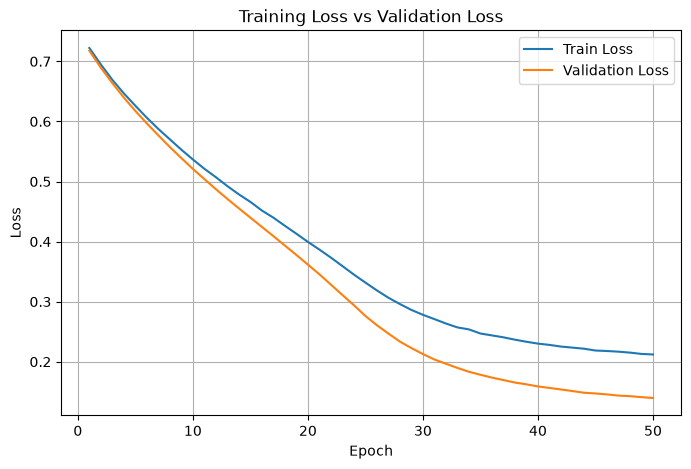

In [26]:
# Plot training and validation loss to monitor learning and possible overfitting.
plt.figure(figsize=(8, 5))

plt.plot(range(1, epochs + 1), train_losses, label="Train Loss")
plt.plot(range(1, epochs + 1), val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [29]:
# Find the epoch that achieved the lowest validation loss.
best_epoch = val_losses.index(min(val_losses))

print(best_epoch, min(val_losses))

49 0.13959713280200958


In [30]:
# Load the model weights saved at the best validation checkpoint.
# The fallback supports PyTorch versions without the weights_only argument.
try:
    ckpt = torch.load(CHECKPOINT_PATH, map_location=torch.device('cpu'), weights_only=True)
except TypeError:
    ckpt = torch.load(CHECKPOINT_PATH, map_location=torch.device('cpu'))

model.load_state_dict(ckpt)
print(f"Training completed! Loaded best checkpoint (val loss {best_val_loss:.4f})")

Training completed! Loaded best checkpoint (val loss 0.1396)


In [32]:
# Evaluate the restored model on unseen test data.
# Convert logits to probabilities, apply a 0.5 threshold, and print classification metrics.
import sklearn

model.eval()

with torch.no_grad():
    test_logits = model(X_test_t)

    test_proba = torch.sigmoid(test_logits).numpy().ravel()

    y_true = y_test_t.numpy().ravel()

    y_pred = (test_proba > 0.5).astype(int)

print(f"y_pred: {y_pred}")

print("------------- Test set Metrics -------------")
print(sklearn.metrics.classification_report(y_true, y_pred, zero_division=0))

print(sklearn.metrics.confusion_matrix(y_true, y_pred))

y_pred: [0 1 0 1 1 1 1 1 0 1 0 1 0 1 1 0 1 0 0 1 1 0 1 1 0 0 1 0 0 0 0 1 0 1 1 0 0
 1 0 1 1 0 1 1 0 0 0 1 1 0 0 0 1 1 1 0 1 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 1
 0 0 1 0 1 1 0 0 1 0 0 0 0 1 0 0 0 1 1 1 1 1 0 1 1 0 1 0 1 0 0 1 0 1 0 1 0
 0 0 1 1 0 0 0 1 1 1 0 1 1 0 1 1 0 0 0 1 0 1 0 1 1 0 0 1 0 1 0 1 0 1 0 0 0
 1 1]
------------- Test set Metrics -------------
              precision    recall  f1-score   support

         0.0       0.90      0.96      0.93        75
         1.0       0.96      0.89      0.92        75

    accuracy                           0.93       150
   macro avg       0.93      0.93      0.93       150
weighted avg       0.93      0.93      0.93       150

[[72  3]
 [ 8 67]]


In [35]:
# Predict the class of a new customer using the trained model.
# Convert the output logit to a probability before applying the classification threshold.
new_customer = [[1.0, 2.0, 3.0]]

new_customer_t = torch.tensor(new_customer, dtype=torch.float32)

model.eval()

with torch.no_grad():
    logit = model(new_customer_t)

    probability = torch.sigmoid(logit)

    prediction = (probability >= 0.5).int()

print("Logit:", logit.item())
print("Probability:", probability.item())
print("Prediction:", prediction.item())

Logit: 7.603504180908203
Probability: 0.9995015859603882
Prediction: 1
